# 4.2 — Accuracy এবং Dummy Model

**Project:** Telco Customer Churn Prediction  
**Model:** Logistic Regression

এই অংশে আমরা যাচাই করব model কতগুলো customer-এর churn সম্পর্কে সঠিক prediction করেছে, `decision threshold` বদলালে `accuracy` কীভাবে বদলায়, এবং খুব সাধারণ একটি `dummy model`-এর তুলনায় Logistic Regression আসলে কতটা ভালো।

> **এই notebook-এ শুধু Section 4.2 আছে।** পরের section-এর বিষয় এখানে শেখানো হয়নি।

## এই অংশে কী কী শিখবে?

1. `Accuracy` কী এবং কীভাবে হিসাব করা হয়।
2. `Decision threshold` বদলালে prediction ও accuracy কেন বদলায়।
3. এমন `dummy model`-এর সঙ্গে তুলনা করা, যেটি সবাইকে বলে “customer churn করবে না”।
4. `Class imbalance` থাকলে accuracy কেন ভুল ধারণা দিতে পারে।

## আগে মূল ধারণাটা বুঝে নাও

আমাদের model সরাসরি শুধু `churn` বা `no churn` বলে না; বরং কোনো customer churn করার **সম্ভাবনা (probability)** দেয়। যেমন, probability `0.78` হলে model অনুমান করছে churn হওয়ার সম্ভাবনা 78%।

এই probability-কে চূড়ান্ত class-এ বদলাতে একটি cutoff ব্যবহার করি, যার নাম **decision threshold**:

- probability `threshold`-এর সমান বা বেশি হলে prediction হবে `churn (1)`;
- probability `threshold`-এর চেয়ে কম হলে prediction হবে `no churn (0)`।

আমরা সাধারণত `0.50` দিয়ে শুরু করি। কিন্তু এটি বাধ্যতামূলক কোনো নিয়ম নয়।

## 4.2 চালানোর জন্য প্রয়োজনীয় Setup

মূল notebook-এ আগের অংশগুলো চালানো থাকলে dataset, train/validation split এবং model আগে থেকেই তৈরি থাকতে পারে। এই ফাইলটি আলাদাভাবে চালানো যাবে বলে প্রয়োজনীয় setup-ও এখানে রাখা হয়েছে। এই setup শুধু Section 4.2-এর হিসাবগুলো চালানোর জন্য।

`data-week-3.csv` ফাইলটি notebook-এর একই folder-এ থাকলে সেটি ব্যবহার হবে। ফাইলটি না থাকলে code internet থেকে lesson-এর public dataset load করার চেষ্টা করবে।

In [ ]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

DATA_PATH = Path("data-week-3.csv")
DATA_URL = (
    "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/"
    "master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    try:
        df = pd.read_csv(DATA_URL)
        print("Dataset internet source থেকে load হয়েছে।")
    except Exception as exc:
        raise FileNotFoundError(
            "Dataset পাওয়া যায়নি। data-week-3.csv ফাইলটি notebook-এর একই folder-এ রাখো, "
            "অথবা internet চালু রেখে notebook চালাও।"
        ) from exc

print(f"Dataset-এর shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

### Data পরিষ্কার এবং ভাগ করা

- column name ছোট হাতের অক্ষরে রূপান্তর করা হচ্ছে, যাতে code-এ একইভাবে ব্যবহার করা যায়।
- `TotalCharges`-এর ফাঁকা value সংখ্যায় রূপান্তরের সময় `NaN` হলে `0` করা হচ্ছে।
- target column `churn`-এ `yes` হলে `1`, আর `no` হলে `0` দেওয়া হচ্ছে।
- dataset-কে `train`, `validation`, এবং `test` অংশে ভাগ করা হচ্ছে। Accuracy-র পরীক্ষা এখানে **validation set**-এ হবে।

`random_state=1` রাখা হয়েছে, যাতে একই dataset দিয়ে আবার run করলে একই ধরনের split পাওয়া যায়।

In [ ]:
# Column name ও categorical value normalize করা।
df.columns = df.columns.str.lower().str.replace(" ", "_")
categorical_columns = list(df.dtypes[df.dtypes == "object"].index)

for column in categorical_columns:
    df[column] = df[column].str.lower().str.replace(" ", "_")

# totalcharges-কে numeric করা; ফাঁকা value 0 দিয়ে পূরণ করা।
df["totalcharges"] = pd.to_numeric(df["totalcharges"], errors="coerce")
df["totalcharges"] = df["totalcharges"].fillna(0)

# Target: yes = 1 (churn), no = 0 (no churn)।
df["churn"] = (df["churn"] == "yes").astype(int)

# প্রথমে 20% test; বাকি data থেকে 25% validation।
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train["churn"].values
y_val = df_val["churn"].values
y_test = df_test["churn"].values

print(f"Training rows:   {len(y_train):,}")
print(f"Validation rows: {len(y_val):,}")
print(f"Test rows:       {len(y_test):,}")

### Logistic Regression train করা এবং probability বের করা

এখানে model-কে আগের অংশের মতো একই feature দিয়ে train করা হচ্ছে। `predict_proba()` প্রতিটি customer-এর class probability দেয়। `[:, 1]` দিয়ে আমরা `churn = 1` হওয়ার probability নিচ্ছি। এই probability-গুলোকেই পরের ধাপগুলোতে বিভিন্ন threshold দিয়ে পরীক্ষা করব।

In [ ]:
numerical = ["tenure", "monthlycharges", "totalcharges"]

categorical = [
    "gender", "seniorcitizen", "partner", "dependents", "phoneservice",
    "multiplelines", "internetservice", "onlinesecurity", "onlinebackup",
    "deviceprotection", "techsupport", "streamingtv", "streamingmovies",
    "contract", "paperlessbilling", "paymentmethod",
]

# প্রতিটি customer row-কে model-এর জন্য feature matrix-এ রূপান্তর।
dv = DictVectorizer(sparse=False)
train_dict = df_train[categorical + numerical].to_dict(orient="records")
X_train = dv.fit_transform(train_dict)

model = LogisticRegression()
model.fit(X_train, y_train)

val_dict = df_val[categorical + numerical].to_dict(orient="records")
X_val = dv.transform(val_dict)
y_pred = model.predict_proba(X_val)[:, 1]

print("Model train হয়েছে; validation set-এর probability তৈরি।")
print(f"Probability range: {y_pred.min():.4f} থেকে {y_pred.max():.4f}")

## 4.2.1 — Accuracy কী?

**Accuracy** বলে মোট prediction-এর মধ্যে কত ভগ্নাংশ সঠিক হয়েছে।

\[
\text{Accuracy} = \frac{\text{সঠিক prediction-এর সংখ্যা}}{\text{মোট prediction-এর সংখ্যা}}
\]

উদাহরণ: 100 জন customer-এর মধ্যে 80 জনের prediction সঠিক হলে accuracy হবে `80 / 100 = 0.80 = 80%`।

এখন threshold `0.50` ব্যবহার করি:

- `y_pred >= 0.50` হলে model বলবে `churn`;
- অন্যথায় বলবে `no churn`।

এরপর prediction-গুলো actual answer (`y_val`)-এর সঙ্গে তুলনা করি।

In [ ]:
threshold_default = 0.50
pred_default = (y_pred >= threshold_default).astype(int)

n_val = len(y_val)
n_correct = int((y_val == pred_default).sum())
accuracy_default = accuracy_score(y_val, pred_default)

print(f"Validation customer: {n_val:,}")
print(f"সঠিক prediction: {n_correct:,} / {n_val:,}")
print(f"Threshold {threshold_default:.2f}-এ Accuracy: {accuracy_default:.4f} ({accuracy_default:.2%})")

### ফলাফল কী বোঝাচ্ছে?

Validation set-এ **1,409 জন customer** আছে। Threshold `0.50`-এ model তাদের মধ্যে **1,132 জনের** prediction সঠিক করেছে।

\[
\text{Accuracy} = \frac{1132}{1409} \approx 0.8034 = 80.34\%
\]

অর্থাৎ, প্রায় 80.34% prediction সঠিক এবং প্রায় 19.66% ভুল। তবে শুধু accuracy জানলে **কোন ধরনের ভুল হচ্ছে**—যেমন churn করতে যাওয়া customer-কে ধরতে পারছে কি না—তা বোঝা যায় না।

## 4.2.2 — Decision threshold বদলালে কী হয়?

`0.50` threshold শুধু একটি starting point। এবার `0.00` থেকে `1.00` পর্যন্ত প্রতি `0.05` ব্যবধানে মোট 21টি threshold পরীক্ষা করব। প্রতিটি threshold-এর জন্য validation accuracy হিসাব করা হবে।

`np.linspace(0, 1, 21)` সমান ব্যবধানে `0` থেকে `1` পর্যন্ত 21টি number তৈরি করে।

In [ ]:
thresholds = np.linspace(0, 1, 21)

scores = []
for threshold in thresholds:
    predictions = y_pred >= threshold
    score = accuracy_score(y_val, predictions)
    scores.append(score)

threshold_results = pd.DataFrame({
    "Threshold": thresholds,
    "Accuracy": scores,
})

display(threshold_results.style.format({
    "Threshold": "{:.2f}",
    "Accuracy": "{:.3f}",
}).highlight_max(subset=["Accuracy"], color="#d9ead3"))

best_index = int(np.argmax(scores))
best_threshold = float(thresholds[best_index])
best_accuracy = float(scores[best_index])
print(f"সেরা tested threshold: {best_threshold:.2f}")
print(f"সর্বোচ্চ validation accuracy: {best_accuracy:.3f} ({best_accuracy:.1%})")

### Threshold comparison-এর ফলাফল

নিচের table-টি code চালানোর প্রত্যাশিত ফলাফল। `Accuracy` column-এ decimal দেওয়া আছে; যেমন `0.803` মানে প্রায় `80.3%`।

| Decision threshold | Accuracy |
|---:|---:|
| 0.00 | 27.4% |
| 0.05 | 50.9% |
| 0.10 | 59.1% |
| 0.15 | 66.6% |
| 0.20 | 71.0% |
| 0.25 | 73.9% |
| 0.30 | 76.0% |
| 0.35 | 77.2% |
| 0.40 | 78.5% |
| 0.45 | 79.3% |
| **0.50** | **80.3%** |
| 0.55 | 80.1% |
| 0.60 | 79.5% |
| 0.65 | 78.6% |
| 0.70 | 76.6% |
| 0.75 | 74.4% |
| 0.80 | 73.5% |
| 0.85 | 72.6% |
| 0.90 | 72.6% |
| 0.95 | 72.6% |
| 1.00 | 72.6% |

### Graph থেকে কী শিখব?

Graph-এ দেখা যায়, threshold `0.00` থেকে বাড়ানোর সঙ্গে accuracy দ্রুত বাড়ে, `0.50`-এর কাছাকাছি সর্বোচ্চ হয়, তারপর ধীরে ধীরে কমে। এই validation set-এ পরীক্ষিত threshold-গুলোর মধ্যে **`0.50` সবচেয়ে ভালো accuracy দিয়েছে: প্রায় 80.34%**।

তবে মনে রাখবে: অন্য dataset বা অন্য business problem-এ সেরা threshold আলাদা হতে পারে। শুধু accuracy বাড়ানোই সবসময় সঠিক লক্ষ্য নয়; churn customer খুঁজে বের করার গুরুত্বও বিবেচনা করতে হয়।

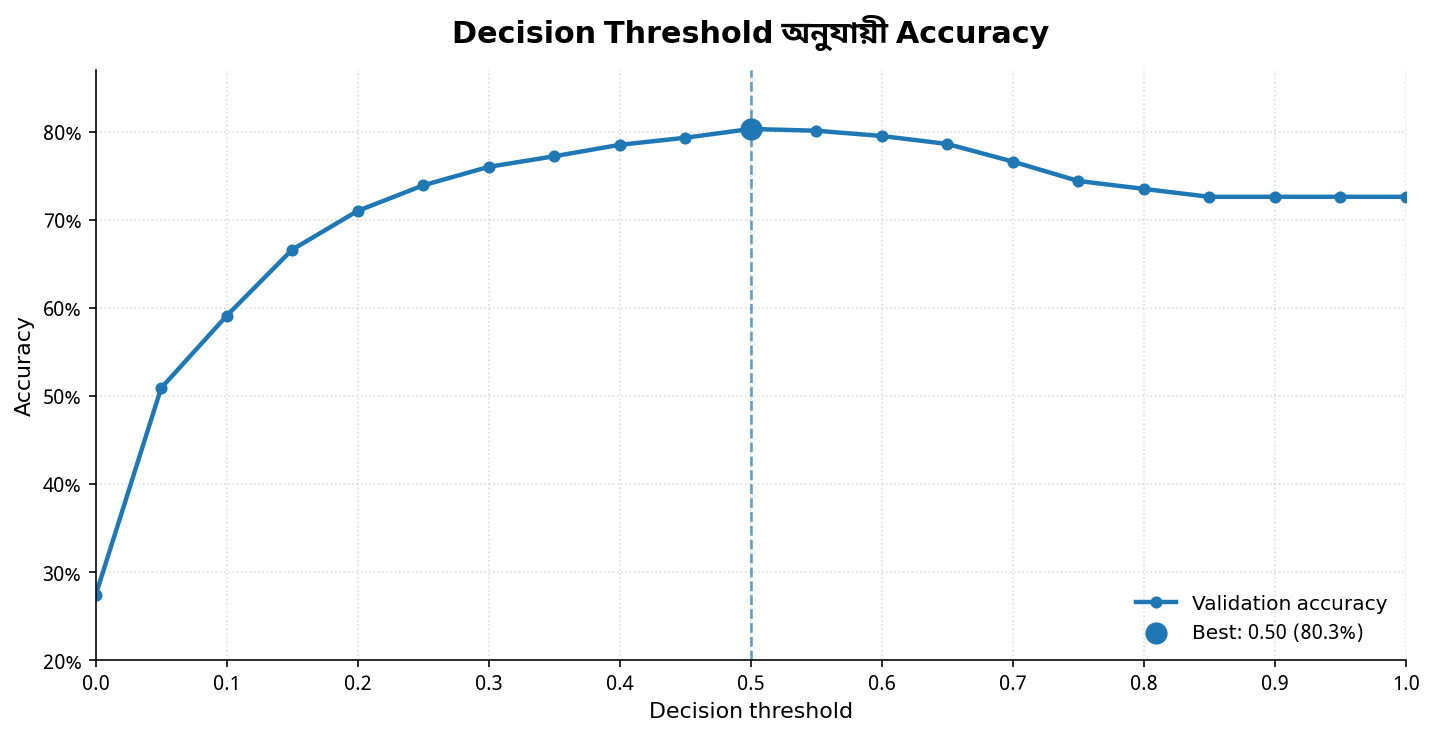

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(thresholds, scores, marker="o", linewidth=2.2, markersize=5,
        label="Validation accuracy")
ax.scatter([best_threshold], [best_accuracy], s=100, zorder=5,
           label=f"Best: {best_threshold:.2f} ({best_accuracy:.1%})")
ax.axvline(best_threshold, linestyle="--", linewidth=1.3, alpha=0.7)
ax.set_title("Decision Threshold অনুযায়ী Accuracy", fontsize=15, weight="bold", pad=14)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Accuracy")
ax.set_xlim(0, 1)
ax.set_ylim(0.2, 0.87)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(True, linestyle=":", alpha=0.45)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

## 4.2.3 — Dummy Model কী?

এবার একটি খুব সাধারণ baseline model ভাবো, যেটি customer-এর কোনো feature দেখে না। এটি **সব customer-কে `no churn (0)`** বলে prediction করে। একেই এখানে `dummy model` বলা হচ্ছে।

কেন এমন model-এর সঙ্গে তুলনা করব? কারণ dataset-এ বেশিরভাগ customer যদি থেকে যায়, তাহলে কিছু না শিখেও সবাইকে `no churn` বললে অনেক prediction সঠিক হতে পারে। তাই Logistic Regression-এর accuracy-কে একটি সহজ baseline-এর সঙ্গে তুলনা করা দরকার।

এই validation set-এ `threshold = 1.00` দিলে model-এর কোনো probability `1.00` না হওয়ায় সব prediction `False`—অর্থাৎ `no churn` হয়।

In [ ]:
# Threshold 1.00-তে prediction-গুলো যাচাই করা।
print("Threshold 1.00-এর ফল:", Counter(y_pred >= 1.0))

# সরাসরি dummy prediction: সবার class 0 (no churn)।
dummy_predictions = np.zeros_like(y_val)
dummy_accuracy = accuracy_score(y_val, dummy_predictions)

print(f"Dummy model Accuracy: {dummy_accuracy:.4f} ({dummy_accuracy:.2%})")
print(f"Logistic Regression Accuracy (threshold 0.50): {accuracy_default:.4f} ({accuracy_default:.2%})")
print(f"পার্থক্য: {(accuracy_default - dummy_accuracy) * 100:.2f} percentage points")

### দুই model-এর তুলনা

| Model | Validation accuracy |
|---|---:|
| Dummy model — সবাই `no churn` | **72.60%** |
| Logistic Regression — threshold `0.50` | **80.34%** |
| পার্থক্য | **7.74 percentage points** |

Logistic Regression ভালো করেছে, কিন্তু dummy model-ও **72.60%** accuracy পেয়েছে—যদিও সেটি কোনো customer-এর তথ্য বিশ্লেষণই করেনি। তাই `80% accuracy` শুনতে যতটা ভালো লাগে, dummy baseline-এর সঙ্গে তুলনা করলে উন্নতিটা ততটা বড় মনে হয় না।

`7.74 percentage points` মানে `80.34% - 72.60%`। এটি 7.74% relative improvement বলার সমান নয়।

## 4.2.4 — Accuracy কেন বিভ্রান্ত করতে পারে? (Class Imbalance)

Validation set-এর দুই class সমান নয়:

- **No churn / থেকে গেছে:** 1,023 জন, অর্থাৎ `72.60%`
- **Churn করেছে:** 386 জন, অর্থাৎ `27.40%`

যখন একটি class অন্য class-এর চেয়ে অনেক বেশি থাকে, তখন তাকে **class imbalance** বলে। এখানে `no churn` হলো majority class এবং `churn` হলো minority class।

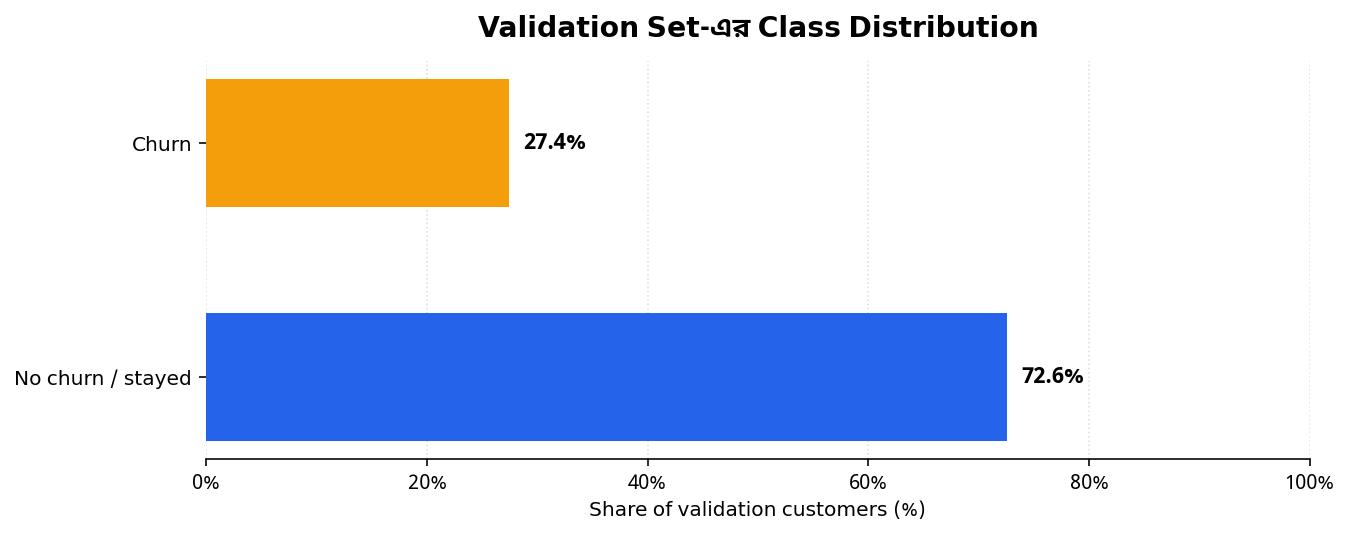

In [ ]:
n_customers = len(y_val)
n_churn = int(y_val.sum())
n_stayed = n_customers - n_churn

churn_pct = n_churn / n_customers * 100
stayed_pct = n_stayed / n_customers * 100

print(f"মোট validation customer: {n_customers:,}")
print(f"No churn / থেকে গেছে: {n_stayed:,} ({stayed_pct:.2f}%)")
print(f"Churn করেছে: {n_churn:,} ({churn_pct:.2f}%)")

fig, ax = plt.subplots(figsize=(9.4, 3.8))
labels = ["No churn / stayed", "Churn"]
values = [stayed_pct, churn_pct]
bars = ax.barh(labels, values, height=0.55)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of validation customers (%)")
ax.set_title("Validation Set-এর Class Distribution", fontsize=14, weight="bold", pad=12)
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.grid(axis="x", linestyle=":", alpha=0.4)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
for bar, value in zip(bars, values):
    ax.text(value + 1.3, bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%", va="center", fontsize=11, weight="bold")
fig.tight_layout()
plt.show()

### Class imbalance থাকলে সমস্যা কোথায়?

Dummy model সবার জন্য `no churn` বলেই `72.60%` accuracy পায়, কারণ validation set-এর `72.60%` customer আসলেই churn করেনি। কিন্তু এই dummy model **একজন churn করা customer-কেও শনাক্ত করে না**।

এটাই মূল সমস্যা: `accuracy` মোট কত prediction সঠিক, সেটি জানায়; কিন্তু model আমাদের জন্য সবচেয়ে গুরুত্বপূর্ণ minority class—এখানে churn করতে যাওয়া customer—খুঁজে পাচ্ছে কি না, তা একা বলে না।

তাই এই problem-এ model মূল্যায়নের জন্য accuracy-কে একমাত্র metric হিসেবে ব্যবহার করা ঠিক হবে না।

## শেষ মুহূর্তের Revision

- **Accuracy:** সঠিক prediction ÷ মোট prediction।
- **Decision threshold:** probability-কে class prediction-এ বদলানোর cutoff। `0.50` একটি পছন্দ, স্থায়ী নিয়ম নয়।
- এই validation set-এ threshold `0.50` সর্বোচ্চ accuracy দিয়েছে: **80.34%**।
- **Dummy model** সবাইকে `no churn` বলেও **72.60%** accuracy পেয়েছে।
- এর কারণ `class imbalance`: `72.60%` customer no churn, আর `27.40%` churn করেছে।
- সুতরাং accuracy একা দেখে churn prediction model কতটা কার্যকর, তা নিশ্চিত হওয়া যায় না।

## ব্যবহৃত Function / Class

| Function / Class | কাজ |
|---|---|
| `np.linspace(start, stop, num)` | নির্দিষ্ট সীমার মধ্যে সমান ব্যবধানে number তৈরি করে। |
| `Counter(values)` | প্রতিটি value কতবার এসেছে তা গোনে। |
| `accuracy_score(y_true, y_pred)` | সঠিক prediction-এর fraction হিসাব করে। |
| `model.predict_proba(X)[:, 1]` | প্রতিটি row-এর `churn = 1` probability দেয়। |
| `np.zeros_like(y_val)` | `y_val`-এর মতো shape-এর একটি array তৈরি করে, যার সব value `0`—এখানে dummy prediction হিসেবে ব্যবহৃত। |